# 04 RFM Segmentation
Segments customers by recency, frequency, and monetary value. Output: `reports/rfm_segment_summary.csv` and chart 07.

In [1]:
# setups and rfm segmentation
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils import load_orders_clean, save_fig

sns.set_theme(style="whitegrid")
df = load_orders_clean()

snapshot = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (df.groupby("customer_unique_id")
         .agg(last_order=("order_purchase_timestamp", "max"),
              frequency=("order_id", "nunique"),
              monetary=("order_value", "sum"))
         .reset_index())
rfm["recency"] = (snapshot - rfm["last_order"]).dt.days

rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["f_score"] = np.select([rfm["frequency"] == 1, rfm["frequency"] == 2], [1, 2], default=3)

print(rfm["frequency"].value_counts().head())

frequency
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64


In [2]:
# segments
conditions = [
    (rfm["frequency"] >= 2) & (rfm["r_score"] >= 3),
    (rfm["frequency"] >= 2),
    (rfm["m_score"] == 4),
    (rfm["r_score"] >= 3),
]
labels = ["Champions (repeat, recent)", "Loyal but lapsing",
          "High-value one-time", "Recent one-time"]
rfm["segment"] = np.select(conditions, labels, default="Lost one-time")

In [3]:
# segment summary
seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"),
               revenue=("monetary", "sum"),
               avg_spend=("monetary", "mean"),
               avg_recency_days=("recency", "mean"))
          .reset_index())
seg["pct_customers"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["pct_revenue"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg = seg.sort_values("revenue", ascending=False).round(1)
print(seg.to_string(index=False))

seg.to_csv("../reports/rfm_segment_summary.csv", index=False)

                   segment  customers   revenue  avg_spend  avg_recency_days  pct_customers  pct_revenue
       High-value one-time      21566 8427057.3      390.8             237.6           23.1         54.7
           Recent one-time      34257 3063850.5       89.4             111.8           36.7         19.9
             Lost one-time      34726 3063299.6       88.2             364.1           37.2         19.9
Champions (repeat, recent)       1544  485942.2      314.7             112.6            1.7          3.2
         Loyal but lapsing       1257  378245.3      300.9             352.6            1.3          2.5


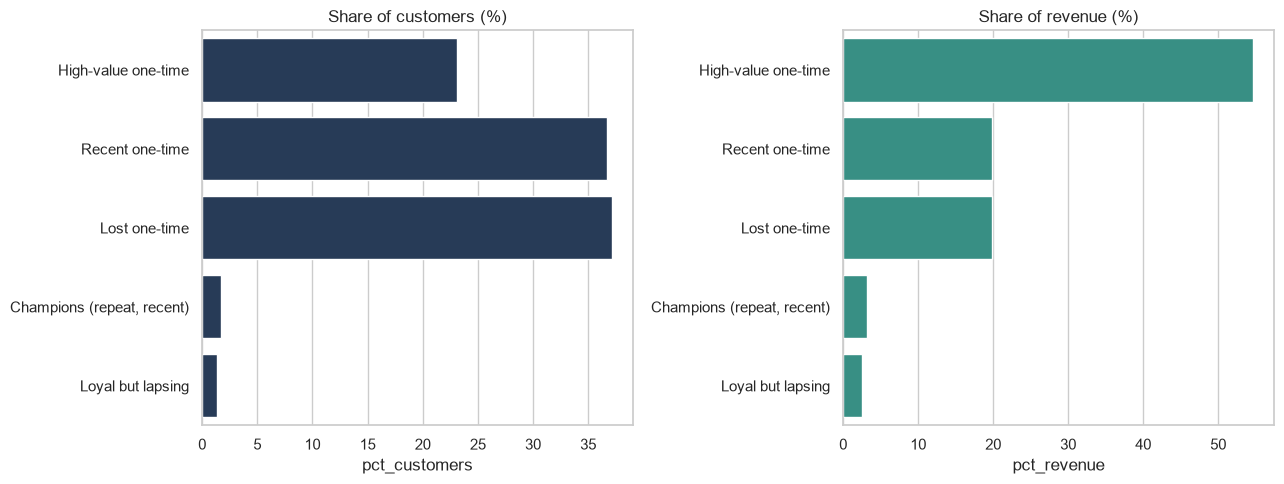

In [4]:
# charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=seg, y="segment", x="pct_customers", color="#1F3A5F", ax=axes[0])
axes[0].set_title("Share of customers (%)"); axes[0].set_ylabel("")
sns.barplot(data=seg, y="segment", x="pct_revenue", color="#2A9D8F", ax=axes[1])
axes[1].set_title("Share of revenue (%)"); axes[1].set_ylabel("")
plt.tight_layout()
save_fig("07_rfm_segments")
plt.show()

## What the segments show
- Repeat buyers (Champions plus Loyal but lapsing) are only 3.0% of customers and 5.7% of order value.
- High-value one-time buyers are 23.1% of customers but 54.7% of order value. This is partly by definition (top-spend quartile), but it means a second purchase from this group matters most.
- Lost one-time buyers (37.2% of customers) average 364 days since their order, so win-back there is likely low yield.

## Actions by segment
- Champions: loyalty rewards and early access.
- Loyal but lapsing: win-back message.
- High-value one-time: second-purchase offer.
- Recent one-time: a follow-up shortly after delivery.
- Lost one-time: low-cost reactivation only.

## Limits
Two years of data, one marketplace, no marketing-cost data.